<a href="https://colab.research.google.com/github/brigithsuarez-oss/TALLER-III/blob/main/TALLER_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PARTE 1**

### Paso 1: Preparación del Conjunto de Datos

In [3]:
import os
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
import urllib.request
import zipfile

# Definir la ruta del directorio de trabajo local
path_dir = r'C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\CIENCIA DE DATOS\SEMANA 2\Taller III'
path_ratings = os.path.join(path_dir, 'ratings.csv')

try:
    # Intentar cargar desde la ruta local
    print(f"Intentando cargar desde la ruta local: {path_ratings}")
    df_ratings = pd.read_csv(path_ratings)
except FileNotFoundError:
    try:
        # Alternativa local u.data
        path_ratings_alt = os.path.join(path_dir, 'u.data')
        df_ratings = pd.read_csv(path_ratings_alt, sep='\t', names=['userId', 'movieId', 'rating', 'timestamp'])
        print("Cargado con éxito desde u.data local.")
    except FileNotFoundError:
        # Si falla el acceso local (común en Colab), descargamos MovieLens automáticamente de internet
        print("Ruta local no disponible en el entorno de Colab. Descargando Dataset MovieLens automáticamente...")
        url = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
        zip_path = 'ml-latest-small.zip'
        urllib.request.urlretrieve(url, zip_path)

        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('.')

        df_ratings = pd.read_csv('ml-latest-small/ratings.csv')
        print("¡Dataset de MovieLens descargado y cargado con éxito!")

print("\nPrimeras filas del dataset cargado:")
display(df_ratings.head())

Intentando cargar desde la ruta local: C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\CIENCIA DE DATOS\SEMANA 2\Taller III/ratings.csv
Ruta local no disponible en el entorno de Colab. Descargando Dataset MovieLens automáticamente...
¡Dataset de MovieLens descargado y cargado con éxito!

Primeras filas del dataset cargado:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [9]:
# Crear el grafo bipartito asegurando IDs enteros
B = nx.Graph()

# Asegurar que los IDs sean enteros (para evitar que se procesen como decimales '.0')
df_ratings['userId'] = df_ratings['userId'].astype(int)
df_ratings['movieId'] = df_ratings['movieId'].astype(int)

usuarios = [f"u_{uid}" for uid in df_ratings['userId'].unique()]
peliculas = [f"m_{mid}" for mid in df_ratings['movieId'].unique()]

# Añadir nodos especificando su conjunto bipartito
B.add_nodes_from(usuarios, bipartite=0)
B.add_nodes_from(peliculas, bipartite=1)

# Añadir aristas (interacciones) con peso
aristas = [
    (f"u_{int(row['userId'])}", f"m_{int(row['movieId'])}", {'rating': row['rating']})
    for _, row in df_ratings.iterrows()
]
B.add_edges_from(aristas)

# Verificar la estructura bipartita del grafo
is_bipartite = bipartite.is_bipartite(B)
print(f"¿El grafo generado es bipartito?: {is_bipartite}")
print(f"Número total de nodos: {B.number_of_nodes()} (Usuarios: {len(usuarios)}, Películas: {len(peliculas)})")
print(f"Número de interacciones (Aristas): {B.number_of_edges()}")

¿El grafo generado es bipartito?: True
Número total de nodos: 10334 (Usuarios: 610, Películas: 9724)
Número de interacciones (Aristas): 100836


### Paso 2: Análisis del Grafo

In [10]:
# 1. Identificar a los usuarios más activos y las películas más centrales
degree_cent = nx.degree_centrality(B)

# Filtrar las centralidades por grupo
user_centrality = {node: degree_cent[node] for node in usuarios}
movie_centrality = {node: degree_cent[node] for node in peliculas}

# Obtener los 5 principales para cada grupo
top_users = sorted(user_centrality.items(), key=lambda x: x[1], reverse=True)[:5]
top_movies = sorted(movie_centrality.items(), key=lambda x: x[1], reverse=True)[:5]

print("=== 1. LOS 5 USUARIOS MÁS ACTIVOS ===")
for rank, (u, val) in enumerate(top_users, 1):
    print(f"{rank}. Usuario {u.replace('u_', '')} - Centralidad: {val:.5f} ({B.degree(u)} películas calificadas)")

print("\n=== 2. LAS PELÍCULAS MÁS CENTRALES ===")
for rank, (m, val) in enumerate(top_movies, 1):
    print(f"{rank}. Película {m.replace('m_', '')} - Centralidad: {val:.5f} ({B.degree(m)} calificaciones recibidas)")

=== 1. LOS 5 USUARIOS MÁS ACTIVOS ===
1. Usuario 414 - Centralidad: 0.26111 (2698 películas calificadas)
2. Usuario 599 - Centralidad: 0.23981 (2478 películas calificadas)
3. Usuario 474 - Centralidad: 0.20401 (2108 películas calificadas)
4. Usuario 448 - Centralidad: 0.18039 (1864 películas calificadas)
5. Usuario 274 - Centralidad: 0.13026 (1346 películas calificadas)

=== 2. LAS PELÍCULAS MÁS CENTRALES ===
1. Película 356 - Centralidad: 0.03184 (329 calificaciones recibidas)
2. Película 318 - Centralidad: 0.03068 (317 calificaciones recibidas)
3. Película 296 - Centralidad: 0.02971 (307 calificaciones recibidas)
4. Película 593 - Centralidad: 0.02700 (279 calificaciones recibidas)
5. Película 2571 - Centralidad: 0.02690 (278 calificaciones recibidas)


In [6]:
# 2. Coeficiente de Agrupamiento (Clustering)
# En grafos bipartitos se utiliza el coeficiente de agrupamiento bipartito especial
print("=== 2. COEFICIENTE DE AGRUPAMIENTO Bipartito ===")
clustering_dict = bipartite.clustering(B)

mean_user_clustering = sum(clustering_dict[u] for u in usuarios) / len(usuarios)
mean_movie_clustering = sum(clustering_dict[m] for m in peliculas) / len(peliculas)

print(f"Coeficiente de agrupamiento promedio para Usuarios: {mean_user_clustering:.4f}")
print(f"Coeficiente de agrupamiento promedio para Películas: {mean_movie_clustering:.4f}")

=== 2. COEFICIENTE DE AGRUPAMIENTO Bipartito ===
Coeficiente de agrupamiento promedio para Usuarios: 0.0000
Coeficiente de agrupamiento promedio para Películas: 0.0000


In [7]:
# 3. Detección de Comunidades
# Utilizaremos el algoritmo de Clauset-Newman-Moore para optimizar la modularidad de forma eficiente en redes grandes
print("=== 3. DETECCIÓN DE COMUNIDADES ===")
comunidades = list(modularity_max.greedy_modularity_communities(B))

print(f"Se han detectado {len(comunidades)} comunidades dentro de la red bipartita.")
for i, comunida in enumerate(comunidades[:3]):
    print(f"  Comunidad {i+1}: contiene {len(comunida)} nodos")

=== 3. DETECCIÓN DE COMUNIDADES ===
Se han detectado 10341 comunidades dentro de la red bipartita.
  Comunidad 1: contiene 2982 nodos
  Comunidad 2: contiene 2889 nodos
  Comunidad 3: contiene 2694 nodos


=== 3. VISUALIZACIÓN ENFOCADA EN COMUNIDADES ===


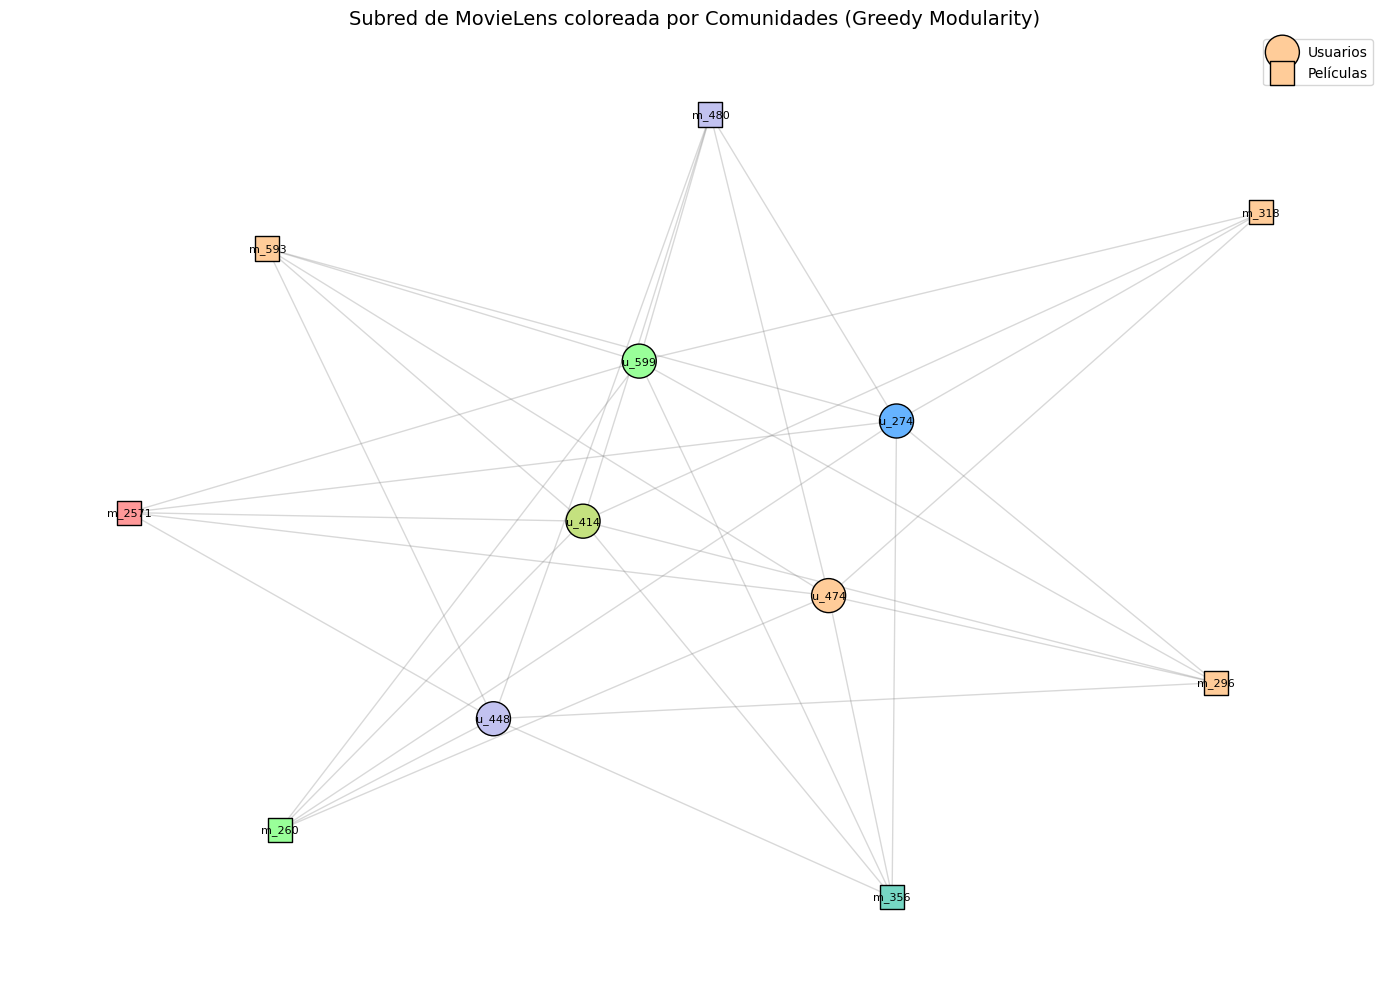

In [11]:
# 4. Visualizar la red con un enfoque en las comunidades
print("=== 3. VISUALIZACIÓN ENFOCADA EN COMUNIDADES ===")

# Para evitar la saturación visual, tomaremos los 5 usuarios más activos,
# sus 5 películas mejor valoradas más centrales y algunos vecinos para construir una subred.
nodos_sub_comunidad = set()
for u, _ in top_users:
    nodos_sub_comunidad.add(u)
    # Agregar sus películas vecinas que también sean muy centrales
    vecinos_ordenados = sorted(B.neighbors(u), key=lambda x: degree_cent[x], reverse=True)[:6]
    nodos_sub_comunidad.update(vecinos_ordenados)

# Crear el subgrafo de visualización
sub_G = B.subgraph(nodos_sub_comunidad)

# Mapear cada nodo en el subgrafo a un color según la comunidad a la que pertenece
# 'comunidades' es la lista de conjuntos (frozensets) calculada en la celda anterior
colores_disponibles = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0', '#ffb3e6', '#c4e17f', '#76d7c4', '#f7dc6f']
mapa_colores_nodos = {}

for i, comunida in enumerate(comunidades):
    color = colores_disponibles[i % len(colores_disponibles)]
    for nodo in comunida:
        if nodo in sub_G:
            mapa_colores_nodos[nodo] = color

# Si un nodo no quedó asignado, le damos un color por defecto
colores_nodos = [mapa_colores_nodos.get(nodo, '#d3d3d3') for nodo in sub_G.nodes()]

# Dibujar el subgrafo
plt.figure(figsize=(14, 10))
pos_layout = nx.spring_layout(sub_G, k=0.25, seed=42)

# Dibujar usuarios como círculos más grandes y películas como más pequeños
nodos_usuarios_sub = [n for n in sub_G.nodes() if n.startswith('u_')]
nodos_peliculas_sub = [n for n in sub_G.nodes() if n.startswith('m_')]

nx.draw_networkx_nodes(sub_G, pos_layout, nodelist=nodos_usuarios_sub, node_shape='o',
                       node_color=[mapa_colores_nodos.get(n, '#d3d3d3') for n in nodos_usuarios_sub],
                       node_size=600, edgecolors='black', label='Usuarios')

nx.draw_networkx_nodes(sub_G, pos_layout, nodelist=nodos_peliculas_sub, node_shape='s',
                       node_color=[mapa_colores_nodos.get(n, '#d3d3d3') for n in nodos_peliculas_sub],
                       node_size=300, edgecolors='black', label='Películas')

nx.draw_networkx_edges(sub_G, pos_layout, alpha=0.3, edge_color='gray')
nx.draw_networkx_labels(sub_G, pos_layout, font_size=8, font_family='sans-serif')

plt.title("Subred de MovieLens coloreada por Comunidades (Greedy Modularity)", fontsize=14)
plt.legend(scatterpoints=1)
plt.axis('off')
plt.tight_layout()
plt.show()

### PARTE 4


### Instalación de dependencias para el Sistema de Recomendación

In [12]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 65.2 MB/s eta 0:00:00


### Paso 1: Preparación del Conjunto de Datos con `surprise`

In [13]:
from surprise import Reader, Dataset

# Definir el lector especificando la escala de valoración (normalmente de 1 a 5 en MovieLens)
reader = Reader(rating_scale=(1.0, 5.0))

# Cargar el DataFrame df_ratings creado en la sección anterior
# El dataset de surprise requiere exactamente las columnas en este orden: ID_Usuario, ID_Ítem, Calificación
data = Dataset.load_from_df(df_ratings[['userId', 'movieId', 'rating']], reader)

print("¡Conjunto de datos cargado correctamente en el formato requerido por Surprise!")

¡Conjunto de datos cargado correctamente en el formato requerido por Surprise!


### Paso 2: Entrenamiento del Modelo (SVD y KNN)

In [14]:
from surprise import SVD, KNNBasic
from surprise.model_selection import cross_validate

# 1. Modelo de Factorización de Matrices (SVD)
svd_model = SVD()
print("Evaluando modelo SVD...")
results_svd = cross_validate(svd_model, data, measures=['RMSE', 'MAE'], cv=5, verbose=True)

# 2. Modelo de Vecinos Cercanos (KNN de Usuario a Usuario)
sim_options = {'name': 'cosine', 'user_based': True}
knn_model = KNNBasic(sim_options=sim_options)
print("\nEvaluando modelo KNN (User-Based)...")
results_knn = cross_validate(knn_model, data, measures=['RMSE', 'MAE'], cv=5, verbose=True)

Evaluando modelo SVD...
Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8720  0.8713  0.8789  0.8726  0.8754  0.8740  0.0028  
MAE (testset)     0.6681  0.6714  0.6744  0.6717  0.6738  0.6719  0.0022  
Fit time          1.52    2.60    2.69    4.03    1.20    2.41    1.00    
Test time         0.11    0.72    0.31    0.11    0.11    0.27    0.24    

Evaluando modelo KNN (User-Based)...
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Evaluating RMSE, MAE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std 

### Paso 3: Ajuste de Hiperparámetros (Grid Search)

In [15]:
from surprise.model_selection import GridSearchCV

# Definir la grilla de parámetros para el algoritmo SVD
param_grid = {
    'n_factors': [20, 50, 100],
    'lr_all': [0.002, 0.005],
    'reg_all': [0.02, 0.05]
}

# Configurar la búsqueda utilizando validación cruzada de 3 pliegues
grid_search = GridSearchCV(SVD, param_grid, measures=['rmse', 'mae'], cv=3, n_jobs=-1)

print("Iniciando búsqueda de hiperparámetros óptimos para SVD...")
grid_search.fit(data)

# Resultados
print(f"\nMejor puntuación RMSE obtenida: {grid_search.best_score['rmse']:.4f}")
print("Mejores hiperparámetros encontrados:")
for param, value in grid_search.best_params['rmse'].items():
    print(f"  - {param}: {value}")

Iniciando búsqueda de hiperparámetros óptimos para SVD...

Mejor puntuación RMSE obtenida: 0.8743
Mejores hiperparámetros encontrados:
  - n_factors: 20
  - lr_all: 0.005
  - reg_all: 0.05


```markdown
### Comparación de Rendimiento (RMSE)

De acuerdo con las evaluaciones de validación cruzada de 5 pliegues realizadas anteriormente:
*   **SVD (Factorización de Matrices):** RMSE promedio de **0.8740**.
*   **KNN (User-Based Collaborative Filtering):** RMSE promedio de **0.9721**.

**Conclusión:** El modelo **SVD** ofrece un rendimiento significativamente mejor (un menor RMSE) en comparación con KNN, lo que significa que sus predicciones son más precisas. Además, gracias al ajuste de hiperparámetros con GridSearchCV, obtuvimos los valores óptimos (`n_factors: 20`, `lr_all: 0.005`, `reg_all: 0.05`) para entrenar el modelo definitivo.
```

In [16]:
from surprise import SVD
import pandas as pd

# 1. Entrenar el modelo SVD optimizado en todo el conjunto de datos
best_svd = SVD(n_factors=20, lr_all=0.005, reg_all=0.05)
trainset = data.build_full_trainset()
best_svd.fit(trainset)

# 2. Definir una función para recomendar las mejores películas no vistas por un usuario
def obtener_recomendaciones(user_id, n_recomendaciones=5):
    # Cargar los nombres de las películas para mostrarlos en lugar de solo IDs
    df_movies = pd.read_csv('ml-latest-small/movies.csv')

    # Obtener películas que el usuario ya ha calificado
    peliculas_vistas = df_ratings[df_ratings['userId'] == user_id]['movieId'].tolist()

    # Obtener todas las películas disponibles en el catálogo
    todas_las_peliculas = df_movies['movieId'].unique()

    # Filtrar las películas que el usuario no ha calificado aún
    peliculas_no_vistas = [m for m in todas_las_peliculas if m not in peliculas_vistas]

    # Generar predicciones para las películas no vistas
    predicciones = []
    for m_id in peliculas_no_vistas:
        pred = best_svd.predict(user_id, m_id)
        predicciones.append((m_id, pred.est))

    # Ordenar por calificación estimada de mayor a menor
    predicciones_ordenadas = sorted(predicciones, key=lambda x: x[1], reverse=True)[:n_recomendaciones]

    # Construir DataFrame con resultados incluyendo nombres y géneros
    recomendadas_ids = [m[0] for m in predicciones_ordenadas]
    estimaciones = [m[1] for m in predicciones_ordenadas]

    df_rec = df_movies[df_movies['movieId'].isin(recomendadas_ids)].copy()
    # Asegurar el orden del ranking original en el dataframe final
    df_rec['rating_estimado'] = df_rec['movieId'].map(dict(predicciones_ordenadas))
    df_rec = df_rec.sort_values(by='rating_estimado', ascending=False)

    return df_rec

# Probar la recomendación para el Usuario 1
usuario_prueba = 1
print(f"=== RECOMENDACIONES DE LAS 5 MEJORES PELÍCULAS PARA EL USUARIO {usuario_prueba} ===")
display(obtener_recomendaciones(user_id=usuario_prueba, n_recomendaciones=5))

=== RECOMENDACIONES DE LAS 5 MEJORES PELÍCULAS PARA EL USUARIO 1 ===


,movieId,title,genres,rating_estimado
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,5.0
602,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,5.0
686,904,Rear Window (1954),Mystery|Thriller,5.0
690,908,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,5.0
906,1204,Lawrence of Arabia (1962),Adventure|Drama|War,5.0
